## 1. Imports and Package Setup

In [ ]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, backend as K
from tensorflow.keras.datasets import mnist

from skimage.metrics import structural_similarity as ssim_metric

print("="*60)
print("LIBRARY VERSIONS")
print("="*60)
print("TensorFlow :", tf.__version__)
print("NumPy      :", np.__version__)
print("Pandas     :", pd.__version__)

LIBRARY VERSIONS
TensorFlow : 2.20.0
NumPy      : 2.1.3
Pandas     : 2.2.3


## 2. Reproducibility and Device Configuration

In [ ]:
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

gpu_devices = tf.config.list_physical_devices('GPU')
if gpu_devices:
    DEVICE = "GPU"
    for gpu in gpu_devices:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except Exception:
            pass
else:
    DEVICE = "CPU"

print("="*60)
print("DEVICE CONFIGURATION")
print("="*60)
print("Selected device :", DEVICE)
print("Random seed     :", SEED)
print("GPUs available  :", len(gpu_devices))

DEVICE CONFIGURATION
Selected device : GPU
Random seed     : 42
GPUs available  : 1


## 3. MNIST Dataset Loading

In [ ]:
(x_train_full, y_train_full), (x_test_full, y_test_full) = mnist.load_data()

print("="*60)
print("RAW MNIST DATASET")
print("="*60)
print("Full training set :", x_train_full.shape)
print("Full test set      :", x_test_full.shape)
print("Pixel value range  : [{}, {}]".format(x_train_full.min(), x_train_full.max()))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
RAW MNIST DATASET
Full training set : (60000, 28, 28)
Full test set      : (10000, 28, 28)
Pixel value range  : [0, 255]
RAW MNIST DATASET
Full training set : (60000, 28, 28)
Full test set      : (10000, 28, 28)
Pixel value range  : [0, 255]


## 4. Dataset Preparation

Recommended laboratory subset: 10,000 training images and 2,000 test images.
Pixel values are normalized from [0,255] to [0,1]. Labels are used only for
visualization (e.g. VAE latent-space colouring) and are never used as reconstruction targets.

In [ ]:
N_TRAIN = 10000
N_TEST = 2000

rng = np.random.default_rng(SEED)
train_idx = rng.choice(len(x_train_full), size=N_TRAIN, replace=False)
test_idx = rng.choice(len(x_test_full), size=N_TEST, replace=False)

x_train = x_train_full[train_idx].astype('float32') / 255.0
y_train = y_train_full[train_idx]
x_test = x_test_full[test_idx].astype('float32') / 255.0
y_test = y_test_full[test_idx]

# Channel dimension for convolutional models
x_train_img = x_train.reshape(-1, 28, 28, 1)
x_test_img = x_test.reshape(-1, 28, 28, 1)

# Flattened vectors for the fully connected autoencoder
x_train_flat = x_train.reshape(-1, 784)
x_test_flat = x_test.reshape(-1, 784)

print("Dataset subset prepared.")

Dataset subset prepared.
Dataset subset prepared.


## 5. Dataset Information

In [ ]:
print("="*60)
print("DATASET INFORMATION")
print("="*60)
print(f"Original training samples : {len(x_train_full)}")
print(f"Original test samples     : {len(x_test_full)}")
print(f"Selected training samples : {x_train_img.shape[0]}")
print(f"Selected test samples     : {x_test_img.shape[0]}")
print(f"Image shape               : {x_train_img.shape[1:]}")
print(f"Flattened vector length   : {x_train_flat.shape[1]}")
print(f"Normalized pixel range    : [{x_train.min():.2f}, {x_train.max():.2f}]")
print(f"Number of classes         : {len(np.unique(y_train))}")
print(f"Class names (digits)      : {sorted(np.unique(y_train).tolist())}")

DATASET INFORMATION
Original training samples : 60000
Original test samples     : 10000
Selected training samples : 10000
Selected test samples     : 2000
Image shape               : (28, 28, 1)
Flattened vector length   : 784
Normalized pixel range    : [0.00, 1.00]
Number of classes         : 10
Class names (digits)      : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


## 6. Sample Image Visualization

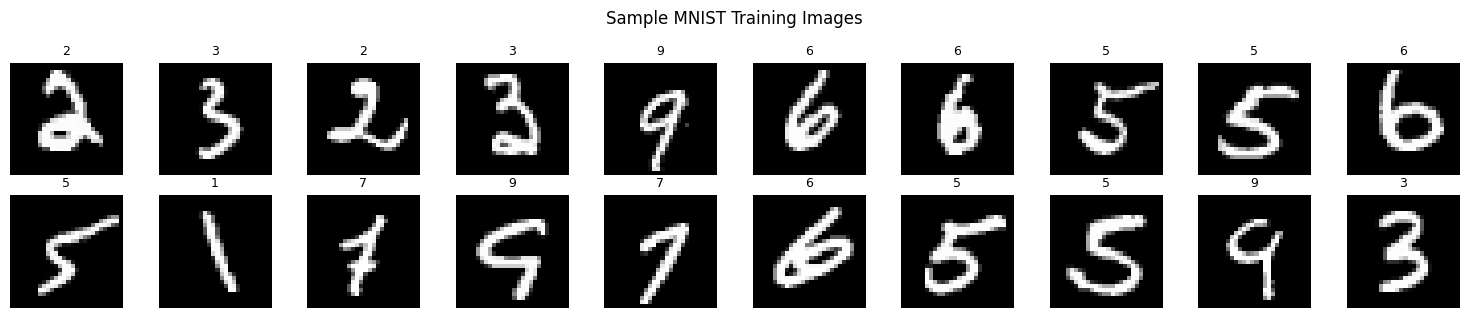

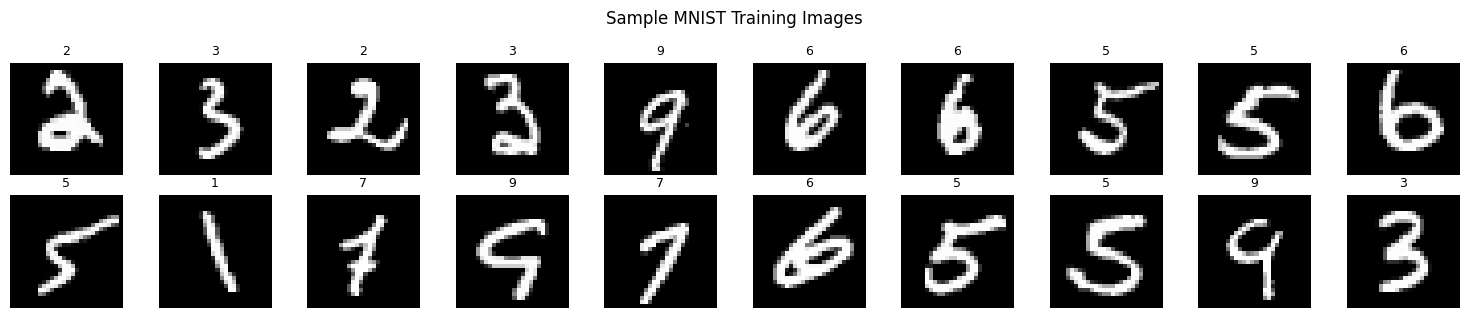

In [ ]:
fig, axes = plt.subplots(2, 10, figsize=(15, 3.2))
for i in range(20):
    ax = axes[i // 10, i % 10]
    ax.imshow(x_train_img[i].squeeze(), cmap='gray')
    ax.set_title(str(y_train[i]), fontsize=9)
    ax.axis('off')
fig.suptitle("Sample MNIST Training Images", fontsize=12)
plt.tight_layout()
plt.savefig("sample_images.png", dpi=150, bbox_inches='tight')
plt.show()

## 7. Fully Connected Autoencoder (FC-AE)

Architecture: `784 -> 128 -> 32 -> 16(latent) -> 32 -> 128 -> 784`,
ReLU in hidden layers, sigmoid output. Loss: Binary Cross-Entropy. Optimizer: Adam (lr = 1e-3).
Batch size 128, 20 epochs.

In [ ]:
LATENT_DIM_FC = 16
EPOCHS_FC = 20
BATCH_SIZE = 128
LEARNING_RATE = 1e-3

def build_fc_autoencoder(latent_dim=16, input_dim=784):
    inputs = layers.Input(shape=(input_dim,), name="fc_input")
    x = layers.Dense(128, activation='relu')(inputs)
    x = layers.Dense(32, activation='relu')(x)
    latent = layers.Dense(latent_dim, activation='relu', name="fc_latent")(x)
    x = layers.Dense(32, activation='relu')(latent)
    x = layers.Dense(128, activation='relu')(x)
    outputs = layers.Dense(input_dim, activation='sigmoid')(x)

    autoencoder = models.Model(inputs, outputs, name=f"FC_Autoencoder_z{latent_dim}")
    encoder = models.Model(inputs, latent, name=f"FC_Encoder_z{latent_dim}")
    autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                         loss='binary_crossentropy')
    return autoencoder, encoder

fc_autoencoder, fc_encoder = build_fc_autoencoder(LATENT_DIM_FC)
fc_autoencoder.summary()
fc_params = fc_autoencoder.count_params()
print("\nTotal trainable parameters (FC-AE):", fc_params)

Model: "FC_Autoencoder_z16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ fc_input (InputLayer)           │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc_latent (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 211,040 (824.38 KB)

 Trainable params: 211,040 (824.38 KB)

 Non-trainable params: 0 (0.00 B)


Total trainable parameters (FC-AE): 211040


### 7.1 FC-AE Training

In [ ]:
print("="*60)
print("TRAINING: FULLY CONNECTED AUTOENCODER")
print("="*60)

start_time = time.time()
history_fc = fc_autoencoder.fit(
    x_train_flat, x_train_flat,
    validation_data=(x_test_flat, x_test_flat),
    epochs=EPOCHS_FC,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=2
)
fc_train_time = time.time() - start_time

fc_final_train_loss = history_fc.history['loss'][-1]
fc_final_val_loss = history_fc.history['val_loss'][-1]

print("\n" + "="*60)
print("FC-AE TRAINING SUMMARY")
print("="*60)
print(f"Training time        : {fc_train_time:.2f} seconds")
print(f"Final training loss   : {fc_final_train_loss:.6f}")
print(f"Final validation loss : {fc_final_val_loss:.6f}")

TRAINING: FULLY CONNECTED AUTOENCODER
Epoch 1/20
79/79 - 6s - 71ms/step - loss: 0.3321 - val_loss: 0.2549
Epoch 2/20
79/79 - 0s - 4ms/step - loss: 0.2305 - val_loss: 0.2053
Epoch 3/20
79/79 - 0s - 6ms/step - loss: 0.1962 - val_loss: 0.1878
Epoch 4/20
79/79 - 1s - 7ms/step - loss: 0.1815 - val_loss: 0.1738
Epoch 5/20
79/79 - 0s - 5ms/step - loss: 0.1690 - val_loss: 0.1635
Epoch 6/20
79/79 - 0s - 4ms/step - loss: 0.1606 - val_loss: 0.1564
Epoch 7/20
79/79 - 0s - 4ms/step - loss: 0.1548 - val_loss: 0.1518
Epoch 8/20
79/79 - 0s - 4ms/step - loss: 0.1508 - val_loss: 0.1484
Epoch 9/20
79/79 - 0s - 4ms/step - loss: 0.1476 - val_loss: 0.1453
Epoch 10/20
79/79 - 0s - 4ms/step - loss: 0.1448 - val_loss: 0.1430
Epoch 11/20
79/79 - 0s - 4ms/step - loss: 0.1427 - val_loss: 0.1409
Epoch 12/20
79/79 - 0s - 4ms/step - loss: 0.1409 - val_loss: 0.1394
Epoch 13/20
79/79 - 1s - 7ms/step - loss: 0.1391 - val_loss: 0.1377
Epoch 14/20
79/79 - 0s - 6ms/step - loss: 0.1373 - val_loss: 0.1359
Epoch 15/20
79/79 

### 7.2 Plot 2 — FC-AE Training and Validation Loss

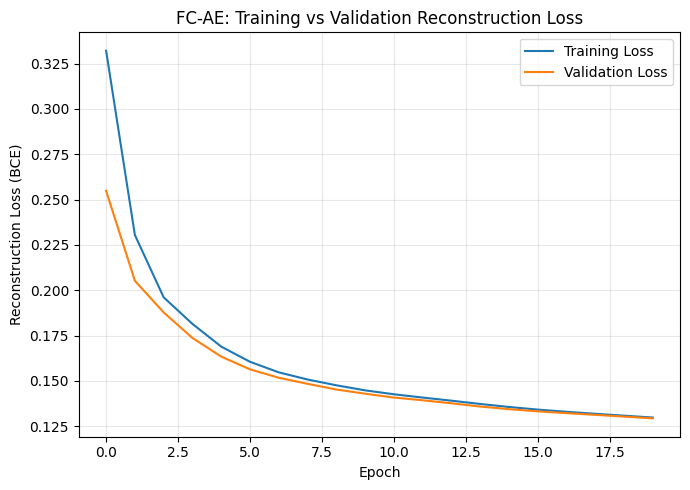

Final train-val loss gap: 0.000449


In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(history_fc.history['loss'], label='Training Loss')
ax.plot(history_fc.history['val_loss'], label='Validation Loss')
ax.set_xlabel("Epoch")
ax.set_ylabel("Reconstruction Loss (BCE)")
ax.set_title("FC-AE: Training vs Validation Reconstruction Loss")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plot2.png", dpi=150, bbox_inches='tight')
plt.show()

gap = abs(fc_final_train_loss - fc_final_val_loss)
print(f"Final train-val loss gap: {gap:.6f}")

### 7.3 Plot 1 — Original vs Reconstructed Images (FC-AE)

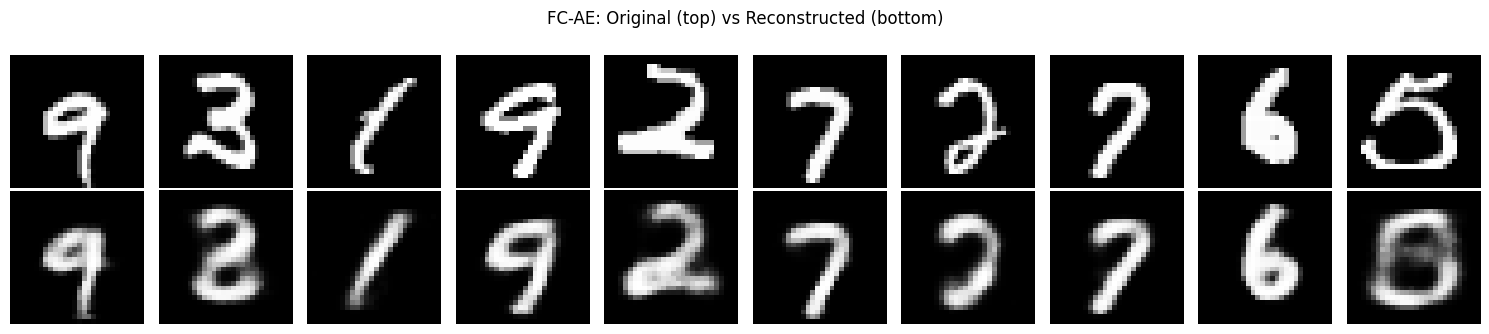

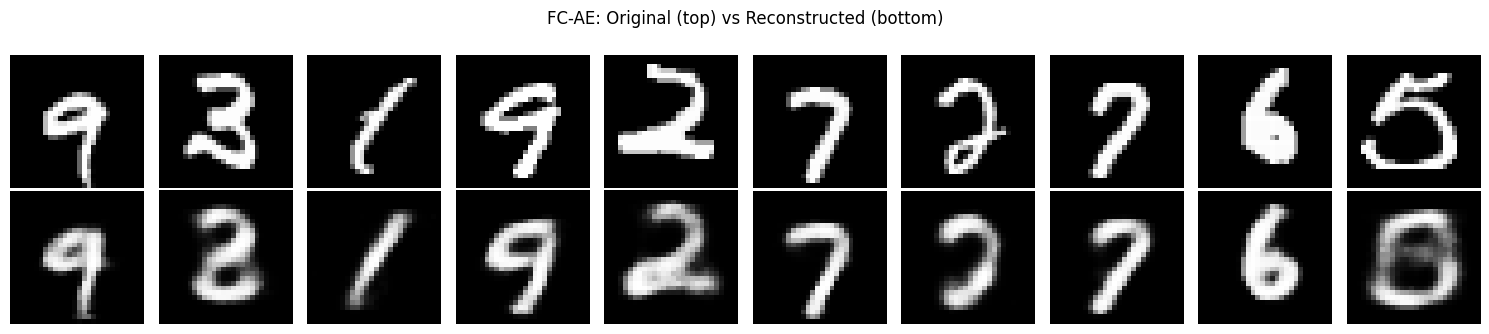

In [ ]:
n_display = 10
fc_reconstructions = fc_autoencoder.predict(x_test_flat[:n_display], verbose=0)

fig, axes = plt.subplots(2, n_display, figsize=(15, 3.4))
for i in range(n_display):
    axes[0, i].imshow(x_test_flat[i].reshape(28, 28), cmap='gray')
    axes[0, i].axis('off')
    axes[1, i].imshow(fc_reconstructions[i].reshape(28, 28), cmap='gray')
    axes[1, i].axis('off')
axes[0, 0].set_ylabel("Original", fontsize=10)
axes[1, 0].set_ylabel("Reconstructed", fontsize=10)
fig.suptitle("FC-AE: Original (top) vs Reconstructed (bottom)", fontsize=12)
plt.tight_layout()
plt.savefig("plot1.png", dpi=150, bbox_inches='tight')
plt.show()

### 7.4 FC-AE Reconstruction Metrics

In [ ]:
def compute_metrics(x_true, x_pred, img_shape=(28, 28)):
    """Compute MSE, MAE and mean SSIM between true and predicted image batches.
    Inputs are expected flattened or reshaped to (N, 28, 28) / (N, 28, 28, 1)."""
    x_true_flat = x_true.reshape(len(x_true), -1)
    x_pred_flat = x_pred.reshape(len(x_pred), -1)

    mse = np.mean((x_true_flat - x_pred_flat) ** 2)
    mae = np.mean(np.abs(x_true_flat - x_pred_flat))

    ssim_vals = []
    x_true_img = x_true.reshape(-1, *img_shape)
    x_pred_img = x_pred.reshape(-1, *img_shape)
    for i in range(len(x_true_img)):
        s = ssim_metric(x_true_img[i], x_pred_img[i], data_range=1.0)
        ssim_vals.append(s)
    mean_ssim = np.mean(ssim_vals)
    return mse, mae, mean_ssim, np.array(ssim_vals)

fc_test_recon = fc_autoencoder.predict(x_test_flat, verbose=0)
fc_mse, fc_mae, fc_ssim, _ = compute_metrics(x_test_flat, fc_test_recon)

print("="*60)
print("FC-AE RECONSTRUCTION METRICS (Test Set)")
print("="*60)
print(f"{'Metric':<15}{'Value':>12}")
print(f"{'Test MSE':<15}{fc_mse:>12.6f}")
print(f"{'Test MAE':<15}{fc_mae:>12.6f}")
print(f"{'Mean SSIM':<15}{fc_ssim:>12.6f}")

FC-AE RECONSTRUCTION METRICS (Test Set)
Metric                Value
Test MSE           0.022270
Test MAE           0.059194
Mean SSIM          0.745986


## 8. Convolutional Autoencoder (CAE)

Architecture: `Conv2D(32) -> MaxPool -> Conv2D(64) -> MaxPool -> Conv2D(64) -> UpSampling ->
Conv2D(32) -> UpSampling -> Conv2D(1, sigmoid)`. Same training protocol (Adam, lr=1e-3,
batch size 128, 20 epochs, BCE loss) is used for controlled comparison with the FC-AE.

In [ ]:
def build_conv_autoencoder():
    inputs = layers.Input(shape=(28, 28, 1), name="cae_input")

    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inputs)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2, padding='same')(x)
    latent = layers.Conv2D(64, 3, activation='relu', padding='same', name="cae_latent")(x)

    x = layers.UpSampling2D(2)(latent)
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    outputs = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)

    autoencoder = models.Model(inputs, outputs, name="Conv_Autoencoder")
    encoder = models.Model(inputs, latent, name="Conv_Encoder")
    autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                         loss='binary_crossentropy')
    return autoencoder, encoder

conv_autoencoder, conv_encoder = build_conv_autoencoder()
conv_autoencoder.summary()
cae_params = conv_autoencoder.count_params()
print("\nTotal trainable parameters (CAE):", cae_params)

Model: "Conv_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cae_input (InputLayer)          │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cae_latent (Conv2D)             │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)


Total trainable parameters (CAE): 74497


### 8.1 CAE Training

In [ ]:
print("="*60)
print("TRAINING: CONVOLUTIONAL AUTOENCODER")
print("="*60)

start_time = time.time()
history_cae = conv_autoencoder.fit(
    x_train_img, x_train_img,
    validation_data=(x_test_img, x_test_img),
    epochs=EPOCHS_FC,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=2
)
cae_train_time = time.time() - start_time

cae_final_train_loss = history_cae.history['loss'][-1]
cae_final_val_loss = history_cae.history['val_loss'][-1]

print("\n" + "="*60)
print("CAE TRAINING SUMMARY")
print("="*60)
print(f"Training time        : {cae_train_time:.2f} seconds")
print(f"Final training loss   : {cae_final_train_loss:.6f}")
print(f"Final validation loss : {cae_final_val_loss:.6f}")

TRAINING: CONVOLUTIONAL AUTOENCODER
Epoch 1/20
79/79 - 9s - 116ms/step - loss: 0.2273 - val_loss: 0.0997
Epoch 2/20
79/79 - 3s - 41ms/step - loss: 0.0926 - val_loss: 0.0865
Epoch 3/20
79/79 - 1s - 8ms/step - loss: 0.0834 - val_loss: 0.0795
Epoch 4/20
79/79 - 1s - 8ms/step - loss: 0.0796 - val_loss: 0.0767
Epoch 5/20
79/79 - 1s - 8ms/step - loss: 0.0768 - val_loss: 0.0749
Epoch 6/20
79/79 - 1s - 8ms/step - loss: 0.0753 - val_loss: 0.0736
Epoch 7/20
79/79 - 1s - 8ms/step - loss: 0.0740 - val_loss: 0.0730
Epoch 8/20
79/79 - 1s - 9ms/step - loss: 0.0731 - val_loss: 0.0719
Epoch 9/20
79/79 - 1s - 8ms/step - loss: 0.0723 - val_loss: 0.0714
Epoch 10/20
79/79 - 1s - 8ms/step - loss: 0.0717 - val_loss: 0.0709
Epoch 11/20
79/79 - 1s - 8ms/step - loss: 0.0712 - val_loss: 0.0704
Epoch 12/20
79/79 - 1s - 10ms/step - loss: 0.0707 - val_loss: 0.0700
Epoch 13/20
79/79 - 1s - 10ms/step - loss: 0.0704 - val_loss: 0.0696
Epoch 14/20
79/79 - 1s - 10ms/step - loss: 0.0700 - val_loss: 0.0693
Epoch 15/20
79/

### 8.2 CAE Reconstruction Metrics

In [ ]:
cae_test_recon = conv_autoencoder.predict(x_test_img, verbose=0)
cae_mse, cae_mae, cae_ssim, _ = compute_metrics(x_test_img, cae_test_recon)

print("="*60)
print("CAE RECONSTRUCTION METRICS (Test Set)")
print("="*60)
print(f"{'Metric':<15}{'Value':>12}")
print(f"{'Test MSE':<15}{cae_mse:>12.6f}")
print(f"{'Test MAE':<15}{cae_mae:>12.6f}")
print(f"{'Mean SSIM':<15}{cae_ssim:>12.6f}")

CAE RECONSTRUCTION METRICS (Test Set)
Metric                Value
Test MSE           0.002419
Test MAE           0.014711
Mean SSIM          0.975349


## 9. Comparing Fully Connected and Convolutional Autoencoders

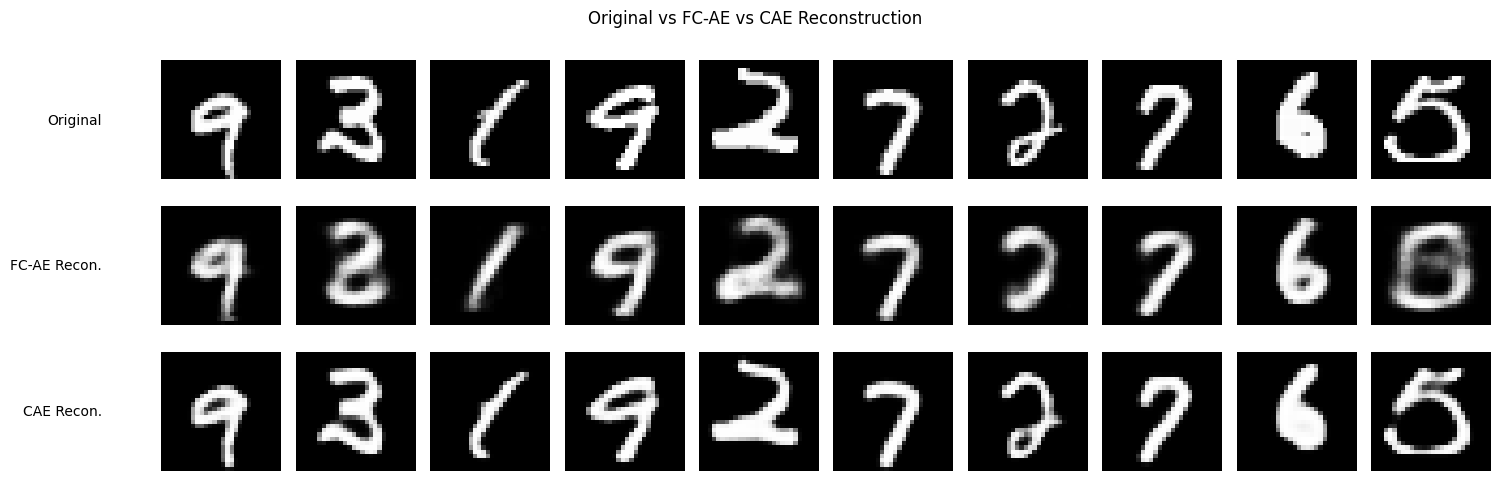

FC-AE vs CAE — SUMMARY TABLE
Model                      MSE       MAE      SSIM      Params
Fully Connected AE     0.02227   0.05919   0.74599      211040
Convolutional AE       0.00242   0.01471   0.97535       74497


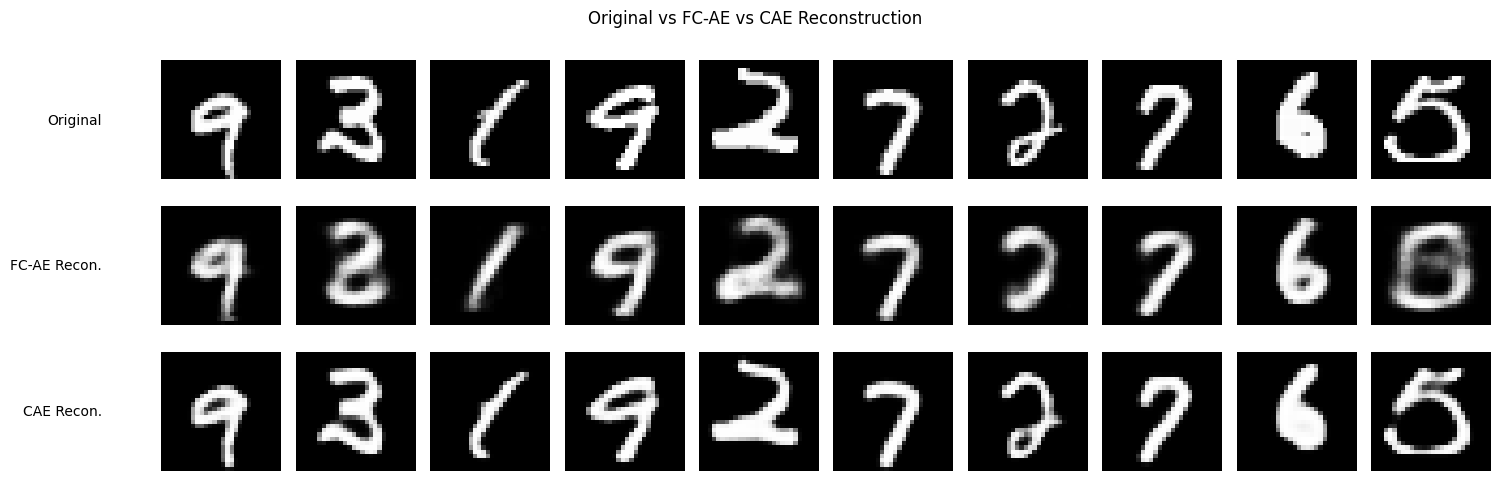

FC-AE vs CAE — SUMMARY TABLE
Model                      MSE       MAE      SSIM      Params
Fully Connected AE     0.02227   0.05919   0.74599      211040
Convolutional AE       0.00242   0.01471   0.97535       74497


In [ ]:
n_display = 10
fc_recon_disp = fc_autoencoder.predict(x_test_flat[:n_display], verbose=0).reshape(-1, 28, 28)
cae_recon_disp = conv_autoencoder.predict(x_test_img[:n_display], verbose=0).reshape(-1, 28, 28)
orig_disp = x_test_img[:n_display].reshape(-1, 28, 28)

fig, axes = plt.subplots(3, n_display, figsize=(15, 5))
row_labels = ["Original", "FC-AE Recon.", "CAE Recon."]
for i in range(n_display):
    axes[0, i].imshow(orig_disp[i], cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(fc_recon_disp[i], cmap='gray'); axes[1, i].axis('off')
    axes[2, i].imshow(cae_recon_disp[i], cmap='gray'); axes[2, i].axis('off')
for r in range(3):
    axes[r, 0].text(-0.5, 0.5, row_labels[r], transform=axes[r, 0].transAxes,
                     ha='right', va='center', fontsize=10)
fig.suptitle("Original vs FC-AE vs CAE Reconstruction", fontsize=12)
plt.tight_layout()
plt.savefig("plot3.png", dpi=150, bbox_inches='tight')
plt.show()

print("="*60)
print("FC-AE vs CAE — SUMMARY TABLE")
print("="*60)
print(f"{'Model':<20}{'MSE':>10}{'MAE':>10}{'SSIM':>10}{'Params':>12}")
print(f"{'Fully Connected AE':<20}{fc_mse:>10.5f}{fc_mae:>10.5f}{fc_ssim:>10.5f}{fc_params:>12}")
print(f"{'Convolutional AE':<20}{cae_mse:>10.5f}{cae_mae:>10.5f}{cae_ssim:>10.5f}{cae_params:>12}")

## 10. Denoising Convolutional Autoencoder

The denoising autoencoder receives a corrupted image but is trained to reconstruct the
original clean image: `noisy_x -> Encoder -> z -> Decoder -> x_hat`, with the clean
image always used as the target. Two corruption types are implemented: Gaussian noise
(sigma in {0.1, 0.2, 0.3}) and salt-and-pepper noise (p in {0.05, 0.10, 0.20}).

In [ ]:
def add_gaussian_noise(images, sigma, seed=SEED):
    rng_local = np.random.default_rng(seed)
    noise = rng_local.normal(loc=0.0, scale=sigma, size=images.shape).astype('float32')
    noisy = images + noise
    return np.clip(noisy, 0.0, 1.0)

def add_salt_pepper_noise(images, p, seed=SEED):
    rng_local = np.random.default_rng(seed)
    noisy = images.copy()
    mask = rng_local.random(images.shape)
    noisy[mask < (p / 2)] = 0.0
    noisy[(mask >= (p / 2)) & (mask < p)] = 1.0
    return noisy

GAUSSIAN_SIGMAS = [0.1, 0.2, 0.3]
SP_PROBS = [0.05, 0.10, 0.20]

TRAIN_SIGMA = 0.2   # noise level used for main denoising model training
x_train_noisy = add_gaussian_noise(x_train_img, TRAIN_SIGMA, seed=SEED)
x_test_noisy = add_gaussian_noise(x_test_img, TRAIN_SIGMA, seed=SEED + 1)

print("="*60)
print("NOISE CONFIGURATION")
print("="*60)
print("Noise types           : Gaussian, Salt-and-Pepper")
print("Gaussian sigma levels :", GAUSSIAN_SIGMAS)
print("Salt-pepper p levels  :", SP_PROBS)
print(f"Training noise level  : Gaussian sigma = {TRAIN_SIGMA}")

NOISE CONFIGURATION
Noise types           : Gaussian, Salt-and-Pepper
Gaussian sigma levels : [0.1, 0.2, 0.3]
Salt-pepper p levels  : [0.05, 0.1, 0.2]
Training noise level  : Gaussian sigma = 0.2


### 10.1 Denoising CAE Architecture and Training

In [ ]:
def build_denoising_cae():
    inputs = layers.Input(shape=(28, 28, 1), name="dcae_input")
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inputs)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2, padding='same')(x)
    latent = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(latent)
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    outputs = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)
    model = models.Model(inputs, outputs, name="Denoising_CAE")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                  loss='binary_crossentropy')
    return model

denoising_cae = build_denoising_cae()
denoising_cae.summary()
dcae_params = denoising_cae.count_params()

print("="*60)
print("TRAINING: DENOISING CONVOLUTIONAL AUTOENCODER")
print("="*60)
print(f"Noise type : Gaussian | sigma = {TRAIN_SIGMA}")

start_time = time.time()
history_dcae = denoising_cae.fit(
    x_train_noisy, x_train_img,
    validation_data=(x_test_noisy, x_test_img),
    epochs=EPOCHS_FC,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=2
)
dcae_train_time = time.time() - start_time
dcae_final_train_loss = history_dcae.history['loss'][-1]
dcae_final_val_loss = history_dcae.history['val_loss'][-1]

print("\n" + "="*60)
print("DENOISING CAE TRAINING SUMMARY")
print("="*60)
print(f"Training time        : {dcae_train_time:.2f} seconds")
print(f"Final training loss   : {dcae_final_train_loss:.6f}")
print(f"Final validation loss : {dcae_final_val_loss:.6f}")

Model: "Denoising_CAE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dcae_input (InputLayer)         │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)

TRAINING: DENOISING CONVOLUTIONAL AUTOENCODER
Noise type : Gaussian | sigma = 0.2
Epoch 1/20
79/79 - 7s - 87ms/step - loss: 0.2725 - val_loss: 0.1260
Epoch 2/20
79/79 - 1s - 9ms/step - loss: 0.1092 - val_loss: 0.0964
Epoch 3/20
79/79 - 1s - 8ms/step - loss: 0.0938 - val_loss: 0.0899
Epoch 4/20
79/79 - 1s - 8ms/step - loss: 0.0884 - val_loss: 0.0853
Epoch 5/20
79/79 - 1s - 8ms/step - loss: 0.0854 - val_loss: 0.0831
Epoch 6/20
79/79 - 1s - 17ms/step - loss: 0.0833 - val_loss: 0.0815
Epoch 7/20
79/79 - 1s - 8ms/step - loss: 0.0818 - val_loss: 0.0803
Epoch 8/20
79/79 - 1s - 8ms/step - loss: 0.0807 - val_loss: 0.0798
Epoch 9/20
79/79 - 1s - 8ms/step - loss: 0.0799 - val_loss: 0.0788
Epoch 10/20
79/79 - 1s - 8ms/step - loss: 0.0792 - val_loss: 0.0782
Epoch 11/20
79/79 - 1s - 8ms/step - loss: 0.0786 - val_loss: 0.0777
Epoch 12/20
79/79 - 1s - 8ms/step - loss: 0.0781 - val_loss: 0.0772
Epoch 13/20
79/79 - 1s - 8ms/step - loss: 0.0776 - val_loss: 0.0770
Epoch 14/20
79/79 - 1s - 9ms/step - loss:

### 10.2 Denoising CAE Metrics

In [ ]:
dcae_test_recon = denoising_cae.predict(x_test_noisy, verbose=0)
dcae_mse, dcae_mae, dcae_ssim, _ = compute_metrics(x_test_img, dcae_test_recon)

print("="*60)
print(f"DENOISING CAE METRICS (Test Set, Gaussian sigma={TRAIN_SIGMA})")
print("="*60)
print(f"{'Metric':<15}{'Value':>12}")
print(f"{'Test MSE':<15}{dcae_mse:>12.6f}")
print(f"{'Test MAE':<15}{dcae_mae:>12.6f}")
print(f"{'Mean SSIM':<15}{dcae_ssim:>12.6f}")

DENOISING CAE METRICS (Test Set, Gaussian sigma=0.2)
Metric                Value
Test MSE           0.004468
Test MAE           0.021070
Mean SSIM          0.948457


### 10.3 Plot 4 — Clean vs Noisy vs Denoised

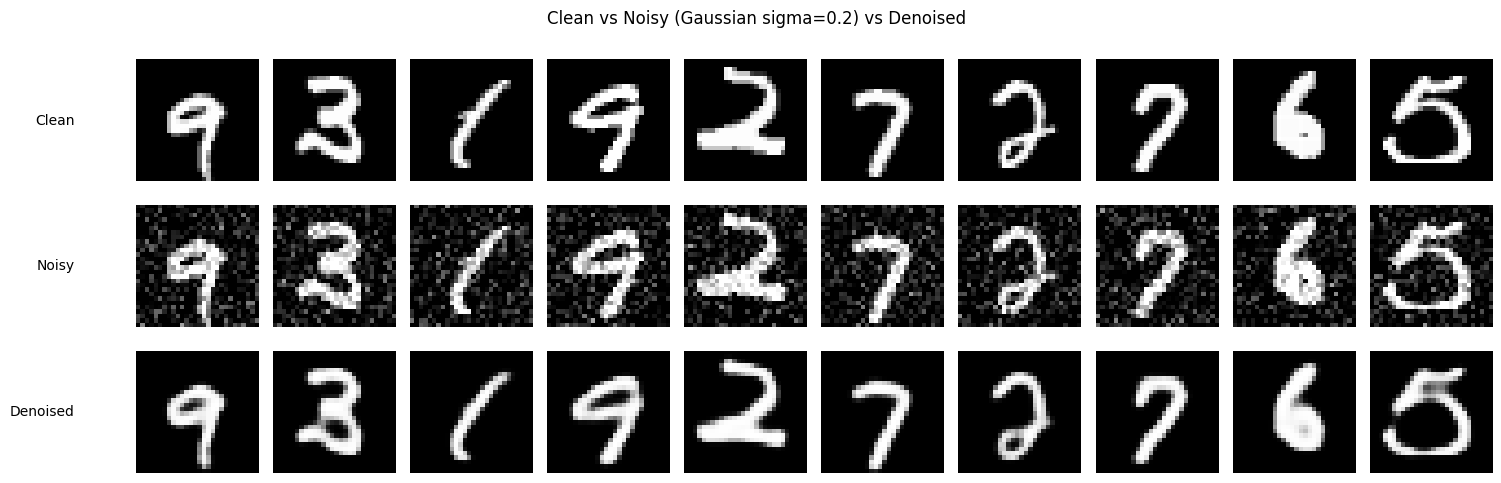

In [ ]:
n_display = 10
clean_disp = x_test_img[:n_display].reshape(-1, 28, 28)
noisy_disp = x_test_noisy[:n_display].reshape(-1, 28, 28)
denoised_disp = dcae_test_recon[:n_display].reshape(-1, 28, 28)

fig, axes = plt.subplots(3, n_display, figsize=(15, 5))
labels = ["Clean", "Noisy", "Denoised"]
for i in range(n_display):
    axes[0, i].imshow(clean_disp[i], cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(noisy_disp[i], cmap='gray'); axes[1, i].axis('off')
    axes[2, i].imshow(denoised_disp[i], cmap='gray'); axes[2, i].axis('off')
for r in range(3):
    axes[r, 0].text(-0.5, 0.5, labels[r], transform=axes[r, 0].transAxes,
                     ha='right', va='center', fontsize=10)
fig.suptitle(f"Clean vs Noisy (Gaussian sigma={TRAIN_SIGMA}) vs Denoised", fontsize=12)
plt.tight_layout()
plt.savefig("plot4.png", dpi=150, bbox_inches='tight')
plt.show()

### 10.4 Plot 5 — Noise Level vs Reconstruction Quality (Gaussian)

GAUSSIAN NOISE LEVEL vs RECONSTRUCTION QUALITY
Sigma              MSE         MAE        SSIM
0.1           0.003462    0.017543    0.962333
0.2           0.004468    0.021070    0.948457
0.3           0.006966    0.029112    0.885719


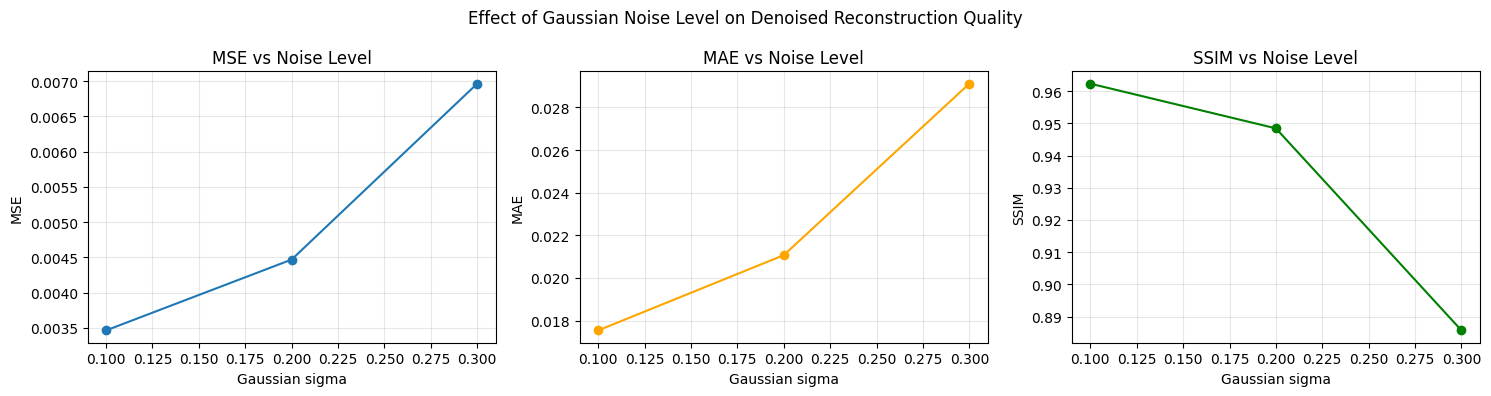

In [ ]:
gaussian_results = []
for sigma in GAUSSIAN_SIGMAS:
    x_test_noisy_s = add_gaussian_noise(x_test_img, sigma, seed=SEED + 1)
    recon_s = denoising_cae.predict(x_test_noisy_s, verbose=0)
    mse_s, mae_s, ssim_s, _ = compute_metrics(x_test_img, recon_s)
    gaussian_results.append((sigma, mse_s, mae_s, ssim_s))

print("="*60)
print("GAUSSIAN NOISE LEVEL vs RECONSTRUCTION QUALITY")
print("="*60)
print(f"{'Sigma':<10}{'MSE':>12}{'MAE':>12}{'SSIM':>12}")
for sigma, mse_s, mae_s, ssim_s in gaussian_results:
    print(f"{sigma:<10}{mse_s:>12.6f}{mae_s:>12.6f}{ssim_s:>12.6f}")

sigmas_arr = [r[0] for r in gaussian_results]
mse_arr = [r[1] for r in gaussian_results]
mae_arr = [r[2] for r in gaussian_results]
ssim_arr = [r[3] for r in gaussian_results]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(sigmas_arr, mse_arr, marker='o'); axes[0].set_title("MSE vs Noise Level")
axes[0].set_xlabel("Gaussian sigma"); axes[0].set_ylabel("MSE"); axes[0].grid(alpha=0.3)
axes[1].plot(sigmas_arr, mae_arr, marker='o', color='orange'); axes[1].set_title("MAE vs Noise Level")
axes[1].set_xlabel("Gaussian sigma"); axes[1].set_ylabel("MAE"); axes[1].grid(alpha=0.3)
axes[2].plot(sigmas_arr, ssim_arr, marker='o', color='green'); axes[2].set_title("SSIM vs Noise Level")
axes[2].set_xlabel("Gaussian sigma"); axes[2].set_ylabel("SSIM"); axes[2].grid(alpha=0.3)
fig.suptitle("Effect of Gaussian Noise Level on Denoised Reconstruction Quality", fontsize=12)
plt.tight_layout()
plt.savefig("plot5.png", dpi=150, bbox_inches='tight')
plt.show()

### 10.5 Salt-and-Pepper Noise — Reconstruction Quality

In [ ]:
sp_results = []
for p in SP_PROBS:
    x_test_sp = add_salt_pepper_noise(x_test_img, p, seed=SEED + 1)
    recon_sp = denoising_cae.predict(x_test_sp, verbose=0)
    mse_sp, mae_sp, ssim_sp, _ = compute_metrics(x_test_img, recon_sp)
    sp_results.append((p, mse_sp, mae_sp, ssim_sp))

print("="*60)
print("SALT-AND-PEPPER NOISE LEVEL vs RECONSTRUCTION QUALITY")
print("(evaluated using the model trained on Gaussian noise)")
print("="*60)
print(f"{'p':<10}{'MSE':>12}{'MAE':>12}{'SSIM':>12}")
for p, mse_sp, mae_sp, ssim_sp in sp_results:
    print(f"{p:<10}{mse_sp:>12.6f}{mae_sp:>12.6f}{ssim_sp:>12.6f}")

SALT-AND-PEPPER NOISE LEVEL vs RECONSTRUCTION QUALITY
(evaluated using the model trained on Gaussian noise)
p                  MSE         MAE        SSIM
0.05          0.004757    0.021012    0.934433
0.1           0.006981    0.027018    0.888367
0.2           0.013783    0.043147    0.767158
SALT-AND-PEPPER NOISE LEVEL vs RECONSTRUCTION QUALITY
(evaluated using the model trained on Gaussian noise)
p                  MSE         MAE        SSIM
0.05          0.004757    0.021012    0.934433
0.1           0.006981    0.027018    0.888367
0.2           0.013783    0.043147    0.767158


## 11. Variational Autoencoder (VAE)

The VAE encoder produces `(mu, log_var)` for a latent dimension of 2 (chosen for direct
visualization). A latent sample is drawn using the reparameterization trick
`z = mu + sigma * epsilon`, `epsilon ~ N(0, I)`. The decoder reconstructs a `28x28x1` image.
The loss combines a Binary Cross-Entropy reconstruction term with the closed-form KL
divergence against a standard normal prior.

In [ ]:
VAE_LATENT_DIM = 2
VAE_EPOCHS = 30

class Sampling(layers.Layer):
    """Reparameterization trick: z = mu + sigma * epsilon, epsilon ~ N(0, I)."""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon


def build_vae_encoder(latent_dim=2):
    inputs = layers.Input(shape=(28, 28, 1), name="vae_encoder_input")
    x = layers.Conv2D(32, 3, activation='relu', strides=2, padding='same')(inputs)
    x = layers.Conv2D(64, 3, activation='relu', strides=2, padding='same')(x)
    x = layers.Flatten()(x)
    x = layers.Dense(64, activation='relu')(x)
    z_mean = layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
    z = Sampling()([z_mean, z_log_var])
    encoder = models.Model(inputs, [z_mean, z_log_var, z], name="VAE_Encoder")
    return encoder


def build_vae_decoder(latent_dim=2):
    latent_inputs = layers.Input(shape=(latent_dim,), name="vae_decoder_input")
    x = layers.Dense(7 * 7 * 64, activation='relu')(latent_inputs)
    x = layers.Reshape((7, 7, 64))(x)
    x = layers.Conv2DTranspose(64, 3, activation='relu', strides=2, padding='same')(x)
    x = layers.Conv2DTranspose(32, 3, activation='relu', strides=2, padding='same')(x)
    outputs = layers.Conv2DTranspose(1, 3, activation='sigmoid', padding='same')(x)
    decoder = models.Model(latent_inputs, outputs, name="VAE_Decoder")
    return decoder


class VAE(models.Model):
    def __init__(self, encoder, decoder, kl_weight=1.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.kl_weight = kl_weight
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.recon_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.recon_loss_tracker, self.kl_loss_tracker]

    def call(self, inputs):
        z_mean, z_log_var, z = self.encoder(inputs)
        return self.decoder(z)

    def _compute_losses(self, data):
        z_mean, z_log_var, z = self.encoder(data)
        reconstruction = self.decoder(z)
        recon_loss = tf.reduce_mean(
            tf.reduce_sum(
                keras.losses.binary_crossentropy(data, reconstruction),
                axis=(1, 2)
            )
        )
        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1)
        )
        total_loss = recon_loss + self.kl_weight * kl_loss
        return total_loss, recon_loss, kl_loss

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]
        with tf.GradientTape() as tape:
            total_loss, recon_loss, kl_loss = self._compute_losses(data)
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {"loss": self.total_loss_tracker.result(),
                "reconstruction_loss": self.recon_loss_tracker.result(),
                "kl_loss": self.kl_loss_tracker.result()}

    def test_step(self, data):
        if isinstance(data, tuple):
            data = data[0]
        total_loss, recon_loss, kl_loss = self._compute_losses(data)
        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {"loss": self.total_loss_tracker.result(),
                "reconstruction_loss": self.recon_loss_tracker.result(),
                "kl_loss": self.kl_loss_tracker.result()}

vae_encoder = build_vae_encoder(VAE_LATENT_DIM)
vae_decoder = build_vae_decoder(VAE_LATENT_DIM)
vae_encoder.summary()
vae_decoder.summary()

vae_params = vae_encoder.count_params() + vae_decoder.count_params()
print("\nTotal trainable parameters (VAE, encoder+decoder):", vae_params)

Model: "VAE_Encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ vae_encoder_input   │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 14, 14,    │        320 │ vae_encoder_inpu… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 7, 7, 64)  │     18,496 │ conv2d_9[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3136)      │          0 │ conv2d_10[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 64)        │    200,768 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        130 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        130 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 219,844 (858.77 KB)

 Trainable params: 219,844 (858.77 KB)

 Non-trainable params: 0 (0.00 B)

Model: "VAE_Decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vae_decoder_input (InputLayer)  │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3136)           │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │           289 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,089 (254.25 KB)

 Trainable params: 65,089 (254.25 KB)

 Non-trainable params: 0 (0.00 B)


Total trainable parameters (VAE, encoder+decoder): 284933


### 11.1 VAE Training

In [ ]:
print("="*60)
print("TRAINING: VARIATIONAL AUTOENCODER (latent_dim=2)")
print("="*60)

vae = VAE(vae_encoder, vae_decoder, kl_weight=1.0)
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE))

start_time = time.time()
history_vae = vae.fit(
    x_train_img, x_train_img,
    validation_data=(x_test_img, x_test_img),
    epochs=VAE_EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=2
)
vae_train_time = time.time() - start_time

vae_final_total = history_vae.history['loss'][-1]
vae_final_recon = history_vae.history['reconstruction_loss'][-1]
vae_final_kl = history_vae.history['kl_loss'][-1]
vae_final_val_total = history_vae.history['val_loss'][-1]
vae_final_val_recon = history_vae.history['val_reconstruction_loss'][-1]
vae_final_val_kl = history_vae.history['val_kl_loss'][-1]

print("\n" + "="*60)
print("VAE TRAINING SUMMARY")
print("="*60)
print(f"Training time             : {vae_train_time:.2f} seconds")
print(f"Final total loss (train)   : {vae_final_total:.4f}")
print(f"Final recon. loss (train)  : {vae_final_recon:.4f}")
print(f"Final KL loss (train)      : {vae_final_kl:.4f}")
print(f"Final total loss (val)     : {vae_final_val_total:.4f}")
print(f"Final recon. loss (val)    : {vae_final_val_recon:.4f}")
print(f"Final KL loss (val)        : {vae_final_val_kl:.4f}")

TRAINING: VARIATIONAL AUTOENCODER (latent_dim=2)
Epoch 1/30
79/79 - 11s - 142ms/step - kl_loss: 4.0071 - loss: 286.4272 - reconstruction_loss: 282.4201 - val_kl_loss: 3.1077 - val_loss: 207.4181 - val_reconstruction_loss: 204.3104
Epoch 2/30
79/79 - 1s - 8ms/step - kl_loss: 3.3544 - loss: 201.2767 - reconstruction_loss: 197.9223 - val_kl_loss: 3.0769 - val_loss: 195.9466 - val_reconstruction_loss: 192.8696
Epoch 3/30
79/79 - 1s - 9ms/step - kl_loss: 3.8617 - loss: 189.1568 - reconstruction_loss: 185.2950 - val_kl_loss: 4.3189 - val_loss: 184.5691 - val_reconstruction_loss: 180.2503
Epoch 4/30
79/79 - 1s - 10ms/step - kl_loss: 4.1876 - loss: 181.5701 - reconstruction_loss: 177.3825 - val_kl_loss: 4.2447 - val_loss: 179.0314 - val_reconstruction_loss: 174.7866
Epoch 5/30
79/79 - 1s - 10ms/step - kl_loss: 4.3566 - loss: 177.2545 - reconstruction_loss: 172.8978 - val_kl_loss: 4.3512 - val_loss: 176.1308 - val_reconstruction_loss: 171.7796
Epoch 6/30
79/79 - 1s - 10ms/step - kl_loss: 4.3697

### 11.2 Plot 9 — VAE Training and Validation Reconstruction Loss

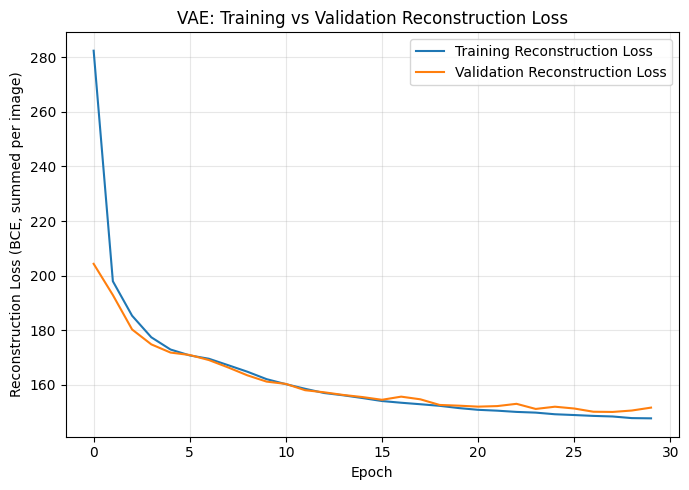

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(history_vae.history['reconstruction_loss'], label='Training Reconstruction Loss')
ax.plot(history_vae.history['val_reconstruction_loss'], label='Validation Reconstruction Loss')
ax.set_xlabel("Epoch")
ax.set_ylabel("Reconstruction Loss (BCE, summed per image)")
ax.set_title("VAE: Training vs Validation Reconstruction Loss")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plot9.png", dpi=150, bbox_inches='tight')
plt.show()

### 11.3 VAE Reconstruction Metrics

In [ ]:
_, _, z_test = vae_encoder.predict(x_test_img, verbose=0)
vae_test_recon = vae_decoder.predict(z_test, verbose=0)
vae_mse, vae_mae, vae_ssim, vae_per_image_mse = compute_metrics(x_test_img, vae_test_recon)

print("="*60)
print("VAE RECONSTRUCTION METRICS (Test Set)")
print("="*60)
print(f"{'Metric':<25}{'Value':>15}")
print(f"{'Reconstruction Loss':<25}{vae_final_val_recon:>15.4f}")
print(f"{'KL Loss':<25}{vae_final_val_kl:>15.4f}")
print(f"{'Total Loss':<25}{vae_final_val_total:>15.4f}")
print(f"{'Test MSE':<25}{vae_mse:>15.6f}")
print(f"{'Test MAE':<25}{vae_mae:>15.6f}")
print(f"{'Mean SSIM':<25}{vae_ssim:>15.6f}")

VAE RECONSTRUCTION METRICS (Test Set)
Metric                             Value
Reconstruction Loss             151.6052
KL Loss                           6.2382
Total Loss                      157.8434
Test MSE                        0.044460
Test MAE                        0.101560
Mean SSIM                       0.516786


## 12. Exploring the VAE Latent Space

Test images are encoded to their 2-D latent mean `z_mean` and plotted, coloured by digit
label. Labels are used only for visualization; the VAE never saw them during training.

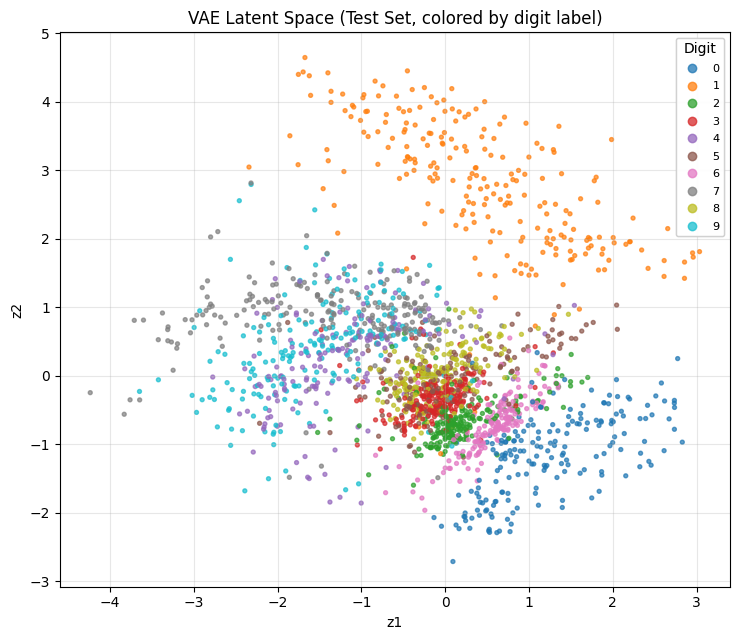

Latent z_mean range: x=[-4.23, 3.04], y=[-2.71, 4.65]


In [ ]:
z_mean_test, z_log_var_test, _ = vae_encoder.predict(x_test_img, verbose=0)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
scatter = ax.scatter(z_mean_test[:, 0], z_mean_test[:, 1], c=y_test, cmap='tab10', s=8, alpha=0.7)
ax.set_xlabel("z1")
ax.set_ylabel("z2")
ax.set_title("VAE Latent Space (Test Set, colored by digit label)")
legend1 = ax.legend(*scatter.legend_elements(), title="Digit", loc="upper right", fontsize=8)
ax.add_artist(legend1)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plot6.png", dpi=150, bbox_inches='tight')
plt.show()

print("Latent z_mean range: x=[{:.2f}, {:.2f}], y=[{:.2f}, {:.2f}]".format(
    z_mean_test[:, 0].min(), z_mean_test[:, 0].max(),
    z_mean_test[:, 1].min(), z_mean_test[:, 1].max()))

## 13. Generating New Images with the VAE

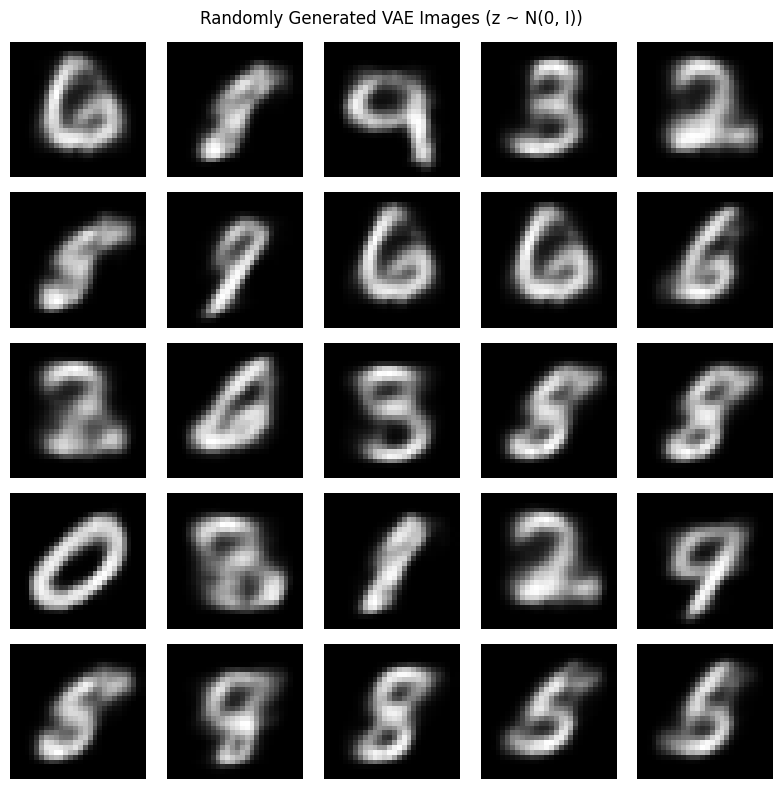

In [ ]:
N_GENERATE = 25
gen_rng = np.random.default_rng(SEED)
z_samples = gen_rng.normal(size=(N_GENERATE, VAE_LATENT_DIM)).astype('float32')
generated_images = vae_decoder.predict(z_samples, verbose=0)

grid_size = 5
fig, axes = plt.subplots(grid_size, grid_size, figsize=(8, 8))
for i in range(N_GENERATE):
    ax = axes[i // grid_size, i % grid_size]
    ax.imshow(generated_images[i].squeeze(), cmap='gray')
    ax.axis('off')
fig.suptitle("Randomly Generated VAE Images (z ~ N(0, I))", fontsize=12)
plt.tight_layout()
plt.savefig("plot7.png", dpi=150, bbox_inches='tight')
plt.show()

## 14. Latent Space Interpolation

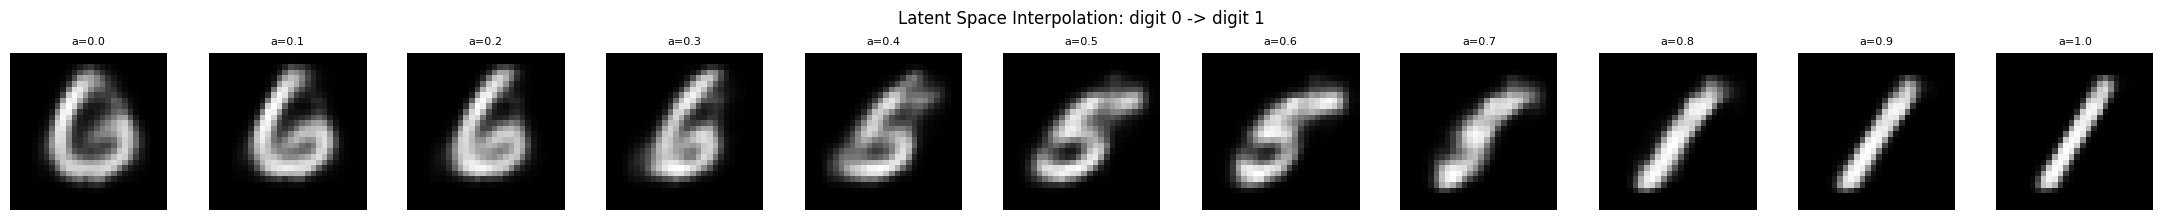

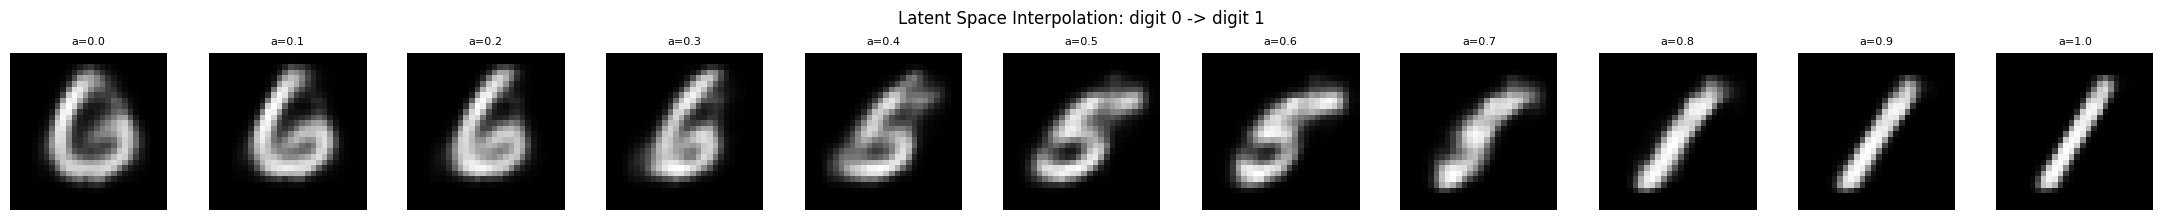

In [ ]:
digit_a, digit_b = 0, 1
idx_a = np.where(y_test == digit_a)[0][0]
idx_b = np.where(y_test == digit_b)[0][0]

z_A = z_mean_test[idx_a]
z_B = z_mean_test[idx_b]

alphas = np.arange(0.0, 1.01, 0.1)
z_interp = np.array([(1 - a) * z_A + a * z_B for a in alphas], dtype='float32')
decoded_interp = vae_decoder.predict(z_interp, verbose=0)

fig, axes = plt.subplots(1, len(alphas), figsize=(2 * len(alphas), 2.2))
for i, ax in enumerate(axes):
    ax.imshow(decoded_interp[i].squeeze(), cmap='gray')
    ax.set_title(f"a={alphas[i]:.1f}", fontsize=8)
    ax.axis('off')
fig.suptitle(f"Latent Space Interpolation: digit {digit_a} -> digit {digit_b}", fontsize=12)
plt.tight_layout()
plt.savefig("plot8.png", dpi=150, bbox_inches='tight')
plt.show()

## 15. Reconstruction Error Distribution

Per-image reconstruction error `e_i = mean_j (x_ij - x_hat_ij)^2` is computed on the test
set using the Convolutional Autoencoder, and its distribution is analysed.

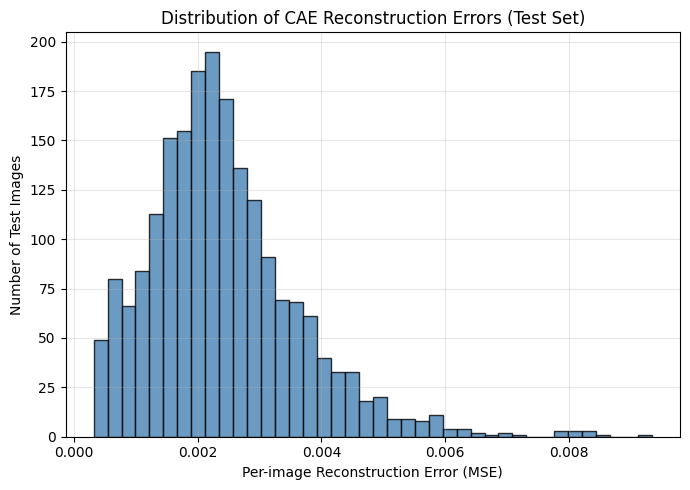

RECONSTRUCTION ERROR STATISTICS (CAE, Test Set)
Minimum error   : 0.000313
Maximum error   : 0.009349
Mean error      : 0.002419
Median error    : 0.002256
90th percentile : 0.003957
95th percentile : 0.004605
99th percentile : 0.006195


In [ ]:
cae_per_image_mse = np.mean((x_test_img.reshape(len(x_test_img), -1) -
                              cae_test_recon.reshape(len(cae_test_recon), -1)) ** 2, axis=1)

fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(cae_per_image_mse, bins=40, color='steelblue', edgecolor='black', alpha=0.8)
ax.set_xlabel("Per-image Reconstruction Error (MSE)")
ax.set_ylabel("Number of Test Images")
ax.set_title("Distribution of CAE Reconstruction Errors (Test Set)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plot10.png", dpi=150, bbox_inches='tight')
plt.show()

print("="*60)
print("RECONSTRUCTION ERROR STATISTICS (CAE, Test Set)")
print("="*60)
print(f"Minimum error   : {cae_per_image_mse.min():.6f}")
print(f"Maximum error   : {cae_per_image_mse.max():.6f}")
print(f"Mean error      : {cae_per_image_mse.mean():.6f}")
print(f"Median error    : {np.median(cae_per_image_mse):.6f}")
print(f"90th percentile : {np.percentile(cae_per_image_mse, 90):.6f}")
print(f"95th percentile : {np.percentile(cae_per_image_mse, 95):.6f}")
print(f"99th percentile : {np.percentile(cae_per_image_mse, 99):.6f}")

## 16. Required High-Error Image Analysis

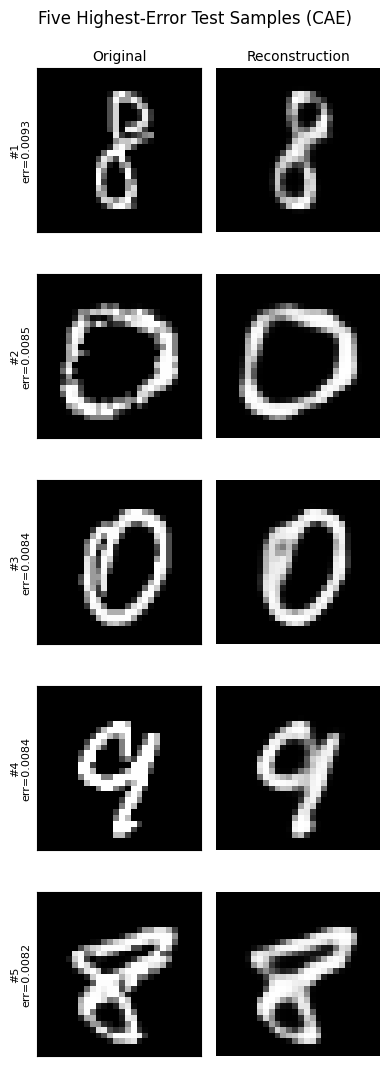

FIVE HIGHEST RECONSTRUCTION-ERROR SAMPLES
Rank  Test Index  True Digit         MSE
1     589         8             0.009349
2     1317        0             0.008477
3     434         0             0.008397
4     949         9             0.008377
5     152         8             0.008226


In [ ]:
n_high = 5
high_error_idx = np.argsort(cae_per_image_mse)[-n_high:][::-1]

fig, axes = plt.subplots(n_high, 2, figsize=(4, 2.2 * n_high))
for row, idx in enumerate(high_error_idx):
    axes[row, 0].imshow(x_test_img[idx].squeeze(), cmap='gray')
    axes[row, 0].set_ylabel(f"#{row+1}\nerr={cae_per_image_mse[idx]:.4f}", fontsize=8)
    axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])
    axes[row, 1].imshow(cae_test_recon[idx].squeeze(), cmap='gray')
    axes[row, 1].axis('off')
axes[0, 0].set_title("Original", fontsize=10)
axes[0, 1].set_title("Reconstruction", fontsize=10)
fig.suptitle("Five Highest-Error Test Samples (CAE)", fontsize=12)
plt.tight_layout()
plt.savefig("high_error_samples.png", dpi=150, bbox_inches='tight')
plt.show()

print("="*60)
print("FIVE HIGHEST RECONSTRUCTION-ERROR SAMPLES")
print("="*60)
print(f"{'Rank':<6}{'Test Index':<12}{'True Digit':<12}{'MSE':>10}")
for rank, idx in enumerate(high_error_idx, 1):
    print(f"{rank:<6}{idx:<12}{y_test[idx]:<12}{cae_per_image_mse[idx]:>10.6f}")

## 17. Consolidated Results — Reconstruction Comparison Across Models

In [ ]:
print("="*60)
print("CONSOLIDATED MODEL COMPARISON")
print("="*60)
print(f"{'Model':<20}{'MSE':>10}{'MAE':>10}{'SSIM':>10}{'Params':>12}{'Time(s)':>10}")
print(f"{'FC Autoencoder':<20}{fc_mse:>10.5f}{fc_mae:>10.5f}{fc_ssim:>10.5f}{fc_params:>12}{fc_train_time:>10.2f}")
print(f"{'Conv. Autoencoder':<20}{cae_mse:>10.5f}{cae_mae:>10.5f}{cae_ssim:>10.5f}{cae_params:>12}{cae_train_time:>10.2f}")
print(f"{'Denoising CAE':<20}{dcae_mse:>10.5f}{dcae_mae:>10.5f}{dcae_ssim:>10.5f}{dcae_params:>12}{dcae_train_time:>10.2f}")
print(f"{'VAE':<20}{vae_mse:>10.5f}{vae_mae:>10.5f}{vae_ssim:>10.5f}{vae_params:>12}{vae_train_time:>10.2f}")

print("\n" + "="*60)
print("VAE LOSS BREAKDOWN (separate from MSE/MAE/SSIM above)")
print("="*60)
print(f"Reconstruction Loss : {vae_final_val_recon:.4f}")
print(f"KL Loss              : {vae_final_val_kl:.4f}")
print(f"Total Loss            : {vae_final_val_total:.4f}")

CONSOLIDATED MODEL COMPARISON
Model                      MSE       MAE      SSIM      Params   Time(s)
FC Autoencoder         0.02227   0.05919   0.74599      211040     13.61
Conv. Autoencoder      0.00242   0.01471   0.97535       74497     24.31
Denoising CAE          0.00447   0.02107   0.94846       74497     20.41
VAE                    0.04446   0.10156   0.51679      284933     32.42

VAE LOSS BREAKDOWN (separate from MSE/MAE/SSIM above)
Reconstruction Loss : 151.6052
KL Loss              : 6.2382
Total Loss            : 157.8434


## 18. Additional Latent-Dimension Study

The fully connected autoencoder is retrained with latent dimensions 2, 8, 16 and 32
(20 epochs each, identical protocol) to study the compression-versus-quality trade-off.

In [ ]:
latent_dims_study = [2, 8, 16, 32]
latent_study_results = []

for dz in latent_dims_study:
    print(f"Training FC-AE with latent_dim={dz} ...")
    model_dz, _ = build_fc_autoencoder(latent_dim=dz)
    start_t = time.time()
    model_dz.fit(x_train_flat, x_train_flat,
                 validation_data=(x_test_flat, x_test_flat),
                 epochs=EPOCHS_FC, batch_size=BATCH_SIZE, shuffle=True, verbose=0)
    elapsed = time.time() - start_t
    recon_dz = model_dz.predict(x_test_flat, verbose=0)
    mse_dz, mae_dz, ssim_dz, _ = compute_metrics(x_test_flat, recon_dz)
    params_dz = model_dz.count_params()
    latent_study_results.append((dz, mse_dz, ssim_dz, params_dz, elapsed))
    print(f"  -> MSE={mse_dz:.6f}  SSIM={ssim_dz:.6f}  Params={params_dz}  Time={elapsed:.1f}s")

print("\n" + "="*60)
print("LATENT DIMENSION STUDY — RESULTS")
print("="*60)
print(f"{'Latent Dim':<12}{'MSE':>10}{'SSIM':>10}{'Params':>12}{'Time(s)':>10}")
for dz, mse_dz, ssim_dz, params_dz, elapsed in latent_study_results:
    print(f"{dz:<12}{mse_dz:>10.5f}{ssim_dz:>10.5f}{params_dz:>12}{elapsed:>10.2f}")

Training FC-AE with latent_dim=2 ...
  -> MSE=0.047181  SSIM=0.470475  Params=210130  Time=12.5s
Training FC-AE with latent_dim=8 ...
  -> MSE=0.027560  SSIM=0.693173  Params=210520  Time=11.7s
Training FC-AE with latent_dim=16 ...
  -> MSE=0.020905  SSIM=0.762303  Params=211040  Time=11.1s
Training FC-AE with latent_dim=32 ...
  -> MSE=0.018366  SSIM=0.790333  Params=212080  Time=13.3s

LATENT DIMENSION STUDY — RESULTS
Latent Dim         MSE      SSIM      Params   Time(s)
2              0.04718   0.47048      210130     12.50
8              0.02756   0.69317      210520     11.67
16             0.02091   0.76230      211040     11.15
32             0.01837   0.79033      212080     13.33


### 18.1 Plot 11 — Latent Dimension vs Reconstruction MSE

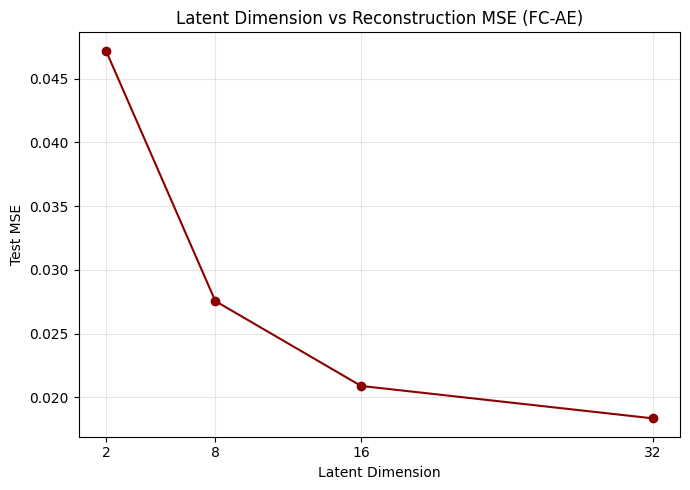

In [ ]:
dims_x = [r[0] for r in latent_study_results]
mse_y = [r[1] for r in latent_study_results]

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(dims_x, mse_y, marker='o', color='darkred')
ax.set_xlabel("Latent Dimension")
ax.set_ylabel("Test MSE")
ax.set_title("Latent Dimension vs Reconstruction MSE (FC-AE)")
ax.set_xticks(dims_x)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plot11.png", dpi=150, bbox_inches='tight')
plt.show()

## 19. Additional Exercises

### 19.1 Exercise 1 — CAE with Latent Dimensions 4, 8, 16, 32

The convolutional autoencoder's bottleneck channel depth is varied (4, 8, 16, 32 filters
in the latent Conv2D layer) and reconstruction quality is compared.

In [ ]:
def build_conv_autoencoder_var_latent(latent_channels):
    inputs = layers.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inputs)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2, padding='same')(x)
    latent = layers.Conv2D(latent_channels, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(latent)
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    outputs = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)
    model = models.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss='binary_crossentropy')
    return model

EX1_EPOCHS = 10
print("Additional Exercise configuration: CAE latent-channel study, epochs =", EX1_EPOCHS)

ex1_channels = [4, 8, 16, 32]
ex1_results = []
for ch in ex1_channels:
    m = build_conv_autoencoder_var_latent(ch)
    m.fit(x_train_img, x_train_img, validation_data=(x_test_img, x_test_img),
          epochs=EX1_EPOCHS, batch_size=BATCH_SIZE, verbose=0)
    recon = m.predict(x_test_img, verbose=0)
    mse_c, mae_c, ssim_c, _ = compute_metrics(x_test_img, recon)
    ex1_results.append((ch, mse_c, mae_c, ssim_c, m.count_params()))
    print(f"latent_channels={ch:<3} -> MSE={mse_c:.5f}  MAE={mae_c:.5f}  SSIM={ssim_c:.5f}  Params={m.count_params()}")

print("\n" + "="*60)
print("EXERCISE 1 RESULTS — CAE LATENT CHANNELS vs QUALITY")
print("="*60)
print(f"{'Channels':<10}{'MSE':>10}{'MAE':>10}{'SSIM':>10}{'Params':>12}")
for ch, mse_c, mae_c, ssim_c, p in ex1_results:
    print(f"{ch:<10}{mse_c:>10.5f}{mae_c:>10.5f}{ssim_c:>10.5f}{p:>12}")

Additional Exercise configuration: CAE latent-channel study, epochs = 10
latent_channels=4   -> MSE=0.00617  MAE=0.02458  SSIM=0.94018  Params=22597
latent_channels=8   -> MSE=0.00469  MAE=0.02119  SSIM=0.95495  Params=26057
latent_channels=16  -> MSE=0.00389  MAE=0.01924  SSIM=0.96059  Params=32977
latent_channels=32  -> MSE=0.00355  MAE=0.01807  SSIM=0.96521  Params=46817

EXERCISE 1 RESULTS — CAE LATENT CHANNELS vs QUALITY
Channels         MSE       MAE      SSIM      Params
4            0.00617   0.02458   0.94018       22597
8            0.00469   0.02119   0.95495       26057
16           0.00389   0.01924   0.96059       32977
32           0.00355   0.01807   0.96521       46817


### 19.2 Exercise 2 — Gaussian vs Salt-and-Pepper Denoising (Same Architecture)

The same denoising CAE architecture is trained separately on Gaussian-corrupted
(sigma=0.2) and salt-and-pepper-corrupted (p=0.10) inputs, then compared.

In [ ]:
EX2_EPOCHS = 15
print("Additional Exercise configuration: Gaussian vs Salt-and-Pepper denoising, epochs =", EX2_EPOCHS)

x_train_gauss = add_gaussian_noise(x_train_img, 0.2, seed=SEED)
x_test_gauss = add_gaussian_noise(x_test_img, 0.2, seed=SEED + 1)
x_train_sp = add_salt_pepper_noise(x_train_img, 0.10, seed=SEED)
x_test_sp = add_salt_pepper_noise(x_test_img, 0.10, seed=SEED + 1)

model_gauss = build_denoising_cae()
model_gauss.fit(x_train_gauss, x_train_img, validation_data=(x_test_gauss, x_test_img),
                 epochs=EX2_EPOCHS, batch_size=BATCH_SIZE, verbose=0)
recon_gauss = model_gauss.predict(x_test_gauss, verbose=0)
mse_g, mae_g, ssim_g, _ = compute_metrics(x_test_img, recon_gauss)

model_sp = build_denoising_cae()
model_sp.fit(x_train_sp, x_train_img, validation_data=(x_test_sp, x_test_img),
             epochs=EX2_EPOCHS, batch_size=BATCH_SIZE, verbose=0)
recon_sp = model_sp.predict(x_test_sp, verbose=0)
mse_s, mae_s, ssim_s, _ = compute_metrics(x_test_img, recon_sp)

print("="*60)
print("EXERCISE 2 RESULTS — GAUSSIAN vs SALT-AND-PEPPER DENOISING")
print("="*60)
print(f"{'Noise Type':<20}{'MSE':>10}{'MAE':>10}{'SSIM':>10}")
print(f"{'Gaussian (0.2)':<20}{mse_g:>10.5f}{mae_g:>10.5f}{ssim_g:>10.5f}")
print(f"{'Salt-Pepper (0.10)':<20}{mse_s:>10.5f}{mae_s:>10.5f}{ssim_s:>10.5f}")

Additional Exercise configuration: Gaussian vs Salt-and-Pepper denoising, epochs = 15
EXERCISE 2 RESULTS — GAUSSIAN vs SALT-AND-PEPPER DENOISING
Noise Type                 MSE       MAE      SSIM
Gaussian (0.2)         0.00469   0.02164   0.94582
Salt-Pepper (0.10)     0.00513   0.02216   0.94401


### 19.3 Exercise 3 — Denoising at Two Noise Levels, SSIM Comparison

The denoising CAE is trained at two distinct Gaussian noise levels (sigma=0.1 and
sigma=0.3) and their SSIM values are compared.

In [ ]:
EX3_EPOCHS = 15
print("Additional Exercise configuration: two-noise-level SSIM comparison, epochs =", EX3_EPOCHS)

ex3_levels = [0.1, 0.3]
ex3_results = []
for sigma in ex3_levels:
    xtr_n = add_gaussian_noise(x_train_img, sigma, seed=SEED)
    xte_n = add_gaussian_noise(x_test_img, sigma, seed=SEED + 1)
    m = build_denoising_cae()
    m.fit(xtr_n, x_train_img, validation_data=(xte_n, x_test_img),
          epochs=EX3_EPOCHS, batch_size=BATCH_SIZE, verbose=0)
    recon = m.predict(xte_n, verbose=0)
    mse_v, mae_v, ssim_v, _ = compute_metrics(x_test_img, recon)
    ex3_results.append((sigma, mse_v, mae_v, ssim_v))

print("="*60)
print("EXERCISE 3 RESULTS — DENOISING AT TWO NOISE LEVELS")
print("="*60)
print(f"{'Sigma':<10}{'MSE':>10}{'MAE':>10}{'SSIM':>10}")
for sigma, mse_v, mae_v, ssim_v in ex3_results:
    print(f"{sigma:<10}{mse_v:>10.5f}{mae_v:>10.5f}{ssim_v:>10.5f}")

Additional Exercise configuration: two-noise-level SSIM comparison, epochs = 15
Additional Exercise configuration: two-noise-level SSIM comparison, epochs = 15
EXERCISE 3 RESULTS — DENOISING AT TWO NOISE LEVELS
Sigma            MSE       MAE      SSIM
0.1          0.00343   0.01819   0.96214
0.3          0.00686   0.02710   0.91654
EXERCISE 3 RESULTS — DENOISING AT TWO NOISE LEVELS
Sigma            MSE       MAE      SSIM
0.1          0.00343   0.01819   0.96214
0.3          0.00686   0.02710   0.91654


### 19.4 Exercise 4 — Conv2DTranspose Decoder vs UpSampling2D Decoder

The CAE decoder is rebuilt using `Conv2DTranspose` layers instead of `UpSampling2D +
Conv2D`, trained identically, and compared against the original UpSampling-based CAE.

In [ ]:
EX4_EPOCHS = 20
print("Additional Exercise configuration: Conv2DTranspose decoder comparison, epochs =", EX4_EPOCHS)

def build_conv_autoencoder_transpose():
    inputs = layers.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inputs)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2, padding='same')(x)
    latent = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.Conv2DTranspose(64, 3, activation='relu', strides=2, padding='same')(latent)
    x = layers.Conv2DTranspose(32, 3, activation='relu', strides=2, padding='same')(x)
    outputs = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)
    model = models.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss='binary_crossentropy')
    return model

model_transpose = build_conv_autoencoder_transpose()
model_transpose.fit(x_train_img, x_train_img, validation_data=(x_test_img, x_test_img),
                     epochs=EX4_EPOCHS, batch_size=BATCH_SIZE, verbose=0)
recon_transpose = model_transpose.predict(x_test_img, verbose=0)
mse_t, mae_t, ssim_t, _ = compute_metrics(x_test_img, recon_transpose)

print("="*60)
print("EXERCISE 4 RESULTS — UPSAMPLING vs CONV2DTRANSPOSE DECODER")
print("="*60)
print(f"{'Decoder Type':<20}{'MSE':>10}{'MAE':>10}{'SSIM':>10}{'Params':>12}")
print(f"{'UpSampling2D (CAE)':<20}{cae_mse:>10.5f}{cae_mae:>10.5f}{cae_ssim:>10.5f}{cae_params:>12}")
print(f"{'Conv2DTranspose':<20}{mse_t:>10.5f}{mae_t:>10.5f}{ssim_t:>10.5f}{model_transpose.count_params():>12}")

Additional Exercise configuration: Conv2DTranspose decoder comparison, epochs = 20
EXERCISE 4 RESULTS — UPSAMPLING vs CONV2DTRANSPOSE DECODER
Decoder Type               MSE       MAE      SSIM      Params
UpSampling2D (CAE)     0.00242   0.01471   0.97535       74497
Conv2DTranspose        0.00209   0.01371   0.97828      111425


### 19.5 Exercise 5 — VAE with Latent Dimension 2 vs 8

A second VAE is trained with latent dimension 8 and compared against the original
latent-dimension-2 VAE in terms of reconstruction quality and loss components.
(The 2-D latent VAE cannot be visualized the same way at dim 8, so only quantitative
comparison is performed.)

In [ ]:
EX5_EPOCHS = 20
print("Additional Exercise configuration: VAE latent_dim=8 comparison, epochs =", EX5_EPOCHS)

vae_encoder_d8 = build_vae_encoder(8)
vae_decoder_d8 = build_vae_decoder(8)
vae_d8 = VAE(vae_encoder_d8, vae_decoder_d8, kl_weight=1.0)
vae_d8.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE))
vae_d8.fit(x_train_img, x_train_img, validation_data=(x_test_img, x_test_img),
           epochs=EX5_EPOCHS, batch_size=BATCH_SIZE, verbose=0)

_, _, z_test_d8 = vae_encoder_d8.predict(x_test_img, verbose=0)
recon_d8 = vae_decoder_d8.predict(z_test_d8, verbose=0)
mse_d8, mae_d8, ssim_d8, _ = compute_metrics(x_test_img, recon_d8)

print("="*60)
print("EXERCISE 5 RESULTS — VAE LATENT DIM 2 vs 8")
print("="*60)
print(f"{'Latent Dim':<12}{'MSE':>10}{'MAE':>10}{'SSIM':>10}")
print(f"{'2':<12}{vae_mse:>10.5f}{vae_mae:>10.5f}{vae_ssim:>10.5f}")
print(f"{'8':<12}{mse_d8:>10.5f}{mae_d8:>10.5f}{ssim_d8:>10.5f}")

Additional Exercise configuration: VAE latent_dim=8 comparison, epochs = 20
EXERCISE 5 RESULTS — VAE LATENT DIM 2 vs 8
Latent Dim         MSE       MAE      SSIM
2              0.04446   0.10156   0.51679
8              0.02084   0.05597   0.77762


### 19.6 Exercise 6 — Effect of Increasing the KL-Loss Contribution (beta-VAE)

The KL term is scaled by beta in {0.5, 1.0, 5.0} (beta-VAE style weighting) and the
resulting reconstruction/KL/total losses and metrics are compared.

In [ ]:
EX6_EPOCHS = 20
print("Additional Exercise configuration: beta-VAE KL-weight study, epochs =", EX6_EPOCHS)

beta_values = [0.5, 1.0, 5.0]
ex6_results = []
for beta in beta_values:
    enc_b = build_vae_encoder(VAE_LATENT_DIM)
    dec_b = build_vae_decoder(VAE_LATENT_DIM)
    vae_b = VAE(enc_b, dec_b, kl_weight=beta)
    vae_b.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE))
    hist_b = vae_b.fit(x_train_img, x_train_img, validation_data=(x_test_img, x_test_img),
                        epochs=EX6_EPOCHS, batch_size=BATCH_SIZE, verbose=0)
    _, _, z_b = enc_b.predict(x_test_img, verbose=0)
    recon_b = dec_b.predict(z_b, verbose=0)
    mse_b, mae_b, ssim_b, _ = compute_metrics(x_test_img, recon_b)
    ex6_results.append((beta,
                         hist_b.history['val_reconstruction_loss'][-1],
                         hist_b.history['val_kl_loss'][-1],
                         hist_b.history['val_loss'][-1],
                         mse_b, ssim_b))

print("="*60)
print("EXERCISE 6 RESULTS — EFFECT OF KL WEIGHT (beta)")
print("="*60)
print(f"{'beta':<8}{'ReconLoss':>12}{'KLLoss':>12}{'TotalLoss':>12}{'MSE':>10}{'SSIM':>10}")
for beta, rl, kl, tl, mse_b, ssim_b in ex6_results:
    print(f"{beta:<8}{rl:>12.4f}{kl:>12.4f}{tl:>12.4f}{mse_b:>10.5f}{ssim_b:>10.5f}")

Additional Exercise configuration: beta-VAE KL-weight study, epochs = 20
EXERCISE 6 RESULTS — EFFECT OF KL WEIGHT (beta)
beta       ReconLoss      KLLoss   TotalLoss       MSE      SSIM
0.5         154.9489      6.5680    158.2329   0.04601   0.49417
1.0         154.9045      5.6024    160.5069   0.04603   0.49551
5.0         158.2331      3.4274    175.3701   0.04750   0.46850


### 19.7 Exercise 7 — Larger Grid of VAE Samples

A larger 10x10 grid (100 images) is generated from the original latent-dim-2 VAE to
assess sample diversity more broadly.

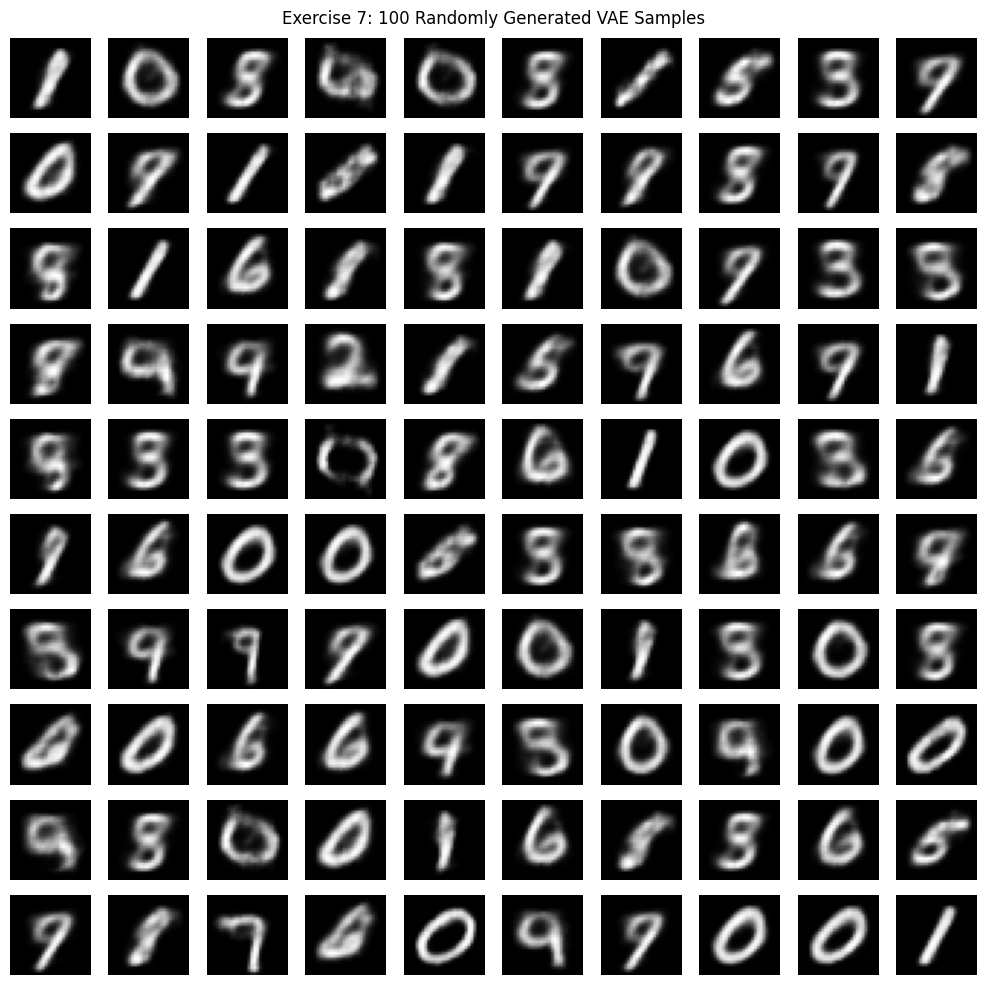

Average per-pixel std across 100 generated samples: 0.1160


In [ ]:
N_LARGE = 100
grid_dim = 10
rng_large = np.random.default_rng(SEED + 7)
z_large = rng_large.normal(size=(N_LARGE, VAE_LATENT_DIM)).astype('float32')
generated_large = vae_decoder.predict(z_large, verbose=0)

fig, axes = plt.subplots(grid_dim, grid_dim, figsize=(10, 10))
for i in range(N_LARGE):
    ax = axes[i // grid_dim, i % grid_dim]
    ax.imshow(generated_large[i].squeeze(), cmap='gray')
    ax.axis('off')
fig.suptitle("Exercise 7: 100 Randomly Generated VAE Samples", fontsize=12)
plt.tight_layout()
plt.savefig("exercise7_large_grid.png", dpi=150, bbox_inches='tight')
plt.show()

pixel_std_across_samples = generated_large.reshape(N_LARGE, -1).std(axis=0).mean()
print(f"Average per-pixel std across {N_LARGE} generated samples: {pixel_std_across_samples:.4f}")

### 19.8 Exercise 8 — Interpolation Between Two Digit Regions

Two additional latent regions (different digit pair) are selected from the latent
scatter plot and interpolated between, to further examine transition smoothness.

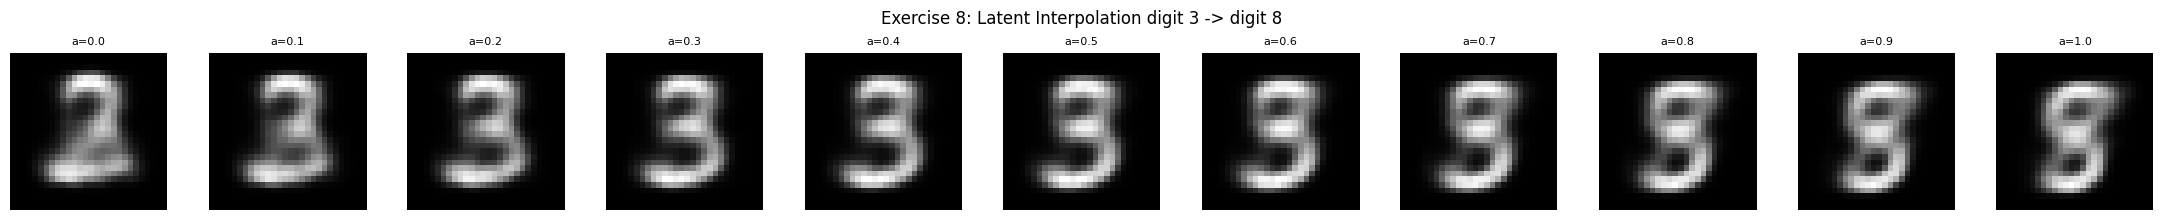

In [ ]:
digit_c, digit_d = 3, 8
idx_c = np.where(y_test == digit_c)[0][0]
idx_d = np.where(y_test == digit_d)[0][0]

z_C = z_mean_test[idx_c]
z_D = z_mean_test[idx_d]

alphas2 = np.arange(0.0, 1.01, 0.1)
z_interp2 = np.array([(1 - a) * z_C + a * z_D for a in alphas2], dtype='float32')
decoded_interp2 = vae_decoder.predict(z_interp2, verbose=0)

fig, axes = plt.subplots(1, len(alphas2), figsize=(2 * len(alphas2), 2.2))
for i, ax in enumerate(axes):
    ax.imshow(decoded_interp2[i].squeeze(), cmap='gray')
    ax.set_title(f"a={alphas2[i]:.1f}", fontsize=8)
    ax.axis('off')
fig.suptitle(f"Exercise 8: Latent Interpolation digit {digit_c} -> digit {digit_d}", fontsize=12)
plt.tight_layout()
plt.savefig("exercise8_interpolation.png", dpi=150, bbox_inches='tight')
plt.show()

## 20. Final Results Summary

In [ ]:
print("="*60)
print("EXPERIMENT 7 FINAL RESULTS SUMMARY")
print("="*60)

print("\nDataset:")
print(f"  Training samples : {x_train_img.shape[0]}   Test samples: {x_test_img.shape[0]}")
print(f"  Image shape      : {x_train_img.shape[1:]}   Normalized range: [0,1]")

print("\nFully Connected Autoencoder (latent=16):")
print(f"  Params={fc_params}  Time={fc_train_time:.1f}s  TrainLoss={fc_final_train_loss:.5f}  ValLoss={fc_final_val_loss:.5f}")
print(f"  MSE={fc_mse:.5f}  MAE={fc_mae:.5f}  SSIM={fc_ssim:.5f}")

print("\nConvolutional Autoencoder:")
print(f"  Params={cae_params}  Time={cae_train_time:.1f}s  TrainLoss={cae_final_train_loss:.5f}  ValLoss={cae_final_val_loss:.5f}")
print(f"  MSE={cae_mse:.5f}  MAE={cae_mae:.5f}  SSIM={cae_ssim:.5f}")

print(f"\nDenoising CAE (Gaussian sigma={TRAIN_SIGMA}):")
print(f"  Params={dcae_params}  Time={dcae_train_time:.1f}s  TrainLoss={dcae_final_train_loss:.5f}  ValLoss={dcae_final_val_loss:.5f}")
print(f"  MSE={dcae_mse:.5f}  MAE={dcae_mae:.5f}  SSIM={dcae_ssim:.5f}")
print("  Gaussian noise-level results:", gaussian_results)
print("  Salt-and-pepper results:", sp_results)

print(f"\nVAE (latent_dim={VAE_LATENT_DIM}):")
print(f"  Params={vae_params}  Time={vae_train_time:.1f}s")
print(f"  ReconLoss={vae_final_val_recon:.4f}  KLLoss={vae_final_val_kl:.4f}  TotalLoss={vae_final_val_total:.4f}")
print(f"  MSE={vae_mse:.5f}  MAE={vae_mae:.5f}  SSIM={vae_ssim:.5f}")

print("\nLatent Dimension Study (FC-AE, dims 2/8/16/32):")
for dz, mse_dz, ssim_dz, params_dz, elapsed in latent_study_results:
    print(f"  dim={dz:<3} MSE={mse_dz:.5f} SSIM={ssim_dz:.5f} Params={params_dz} Time={elapsed:.1f}s")

print("\nAdditional Exercises:")
print("  Ex1 (CAE latent channels 4/8/16/32):", ex1_results)
print(f"  Ex2 (Gaussian vs Salt-Pepper): Gaussian MSE={mse_g:.5f} SSIM={ssim_g:.5f} | SaltPepper MSE={mse_s:.5f} SSIM={ssim_s:.5f}")
print("  Ex3 (Two noise levels SSIM):", ex3_results)
print(f"  Ex4 (UpSampling vs Conv2DTranspose): UpSampling SSIM={cae_ssim:.5f} | Transpose SSIM={ssim_t:.5f}")
print(f"  Ex5 (VAE latent 2 vs 8): dim2 SSIM={vae_ssim:.5f} | dim8 SSIM={ssim_d8:.5f}")
print("  Ex6 (beta-VAE KL weight study):", ex6_results)
print(f"  Ex7 (100-sample generation grid): mean pixel std={pixel_std_across_samples:.4f}")
print(f"  Ex8 (digit {digit_c}->{digit_d} interpolation): completed, see exercise8_interpolation.png")

print("\nGenerated Figures:")
fig_files = ["plot1.png","plot2.png","plot3.png","plot4.png","plot5.png","plot6.png",
             "plot7.png","plot8.png","plot9.png","plot10.png","plot11.png",
             "high_error_samples.png","sample_images.png",
             "exercise7_large_grid.png","exercise8_interpolation.png"]
for fname in fig_files:
    status = "OK" if os.path.exists(fname) else "MISSING"
    print(f"  {fname:<30} {status}")

print("\n" + "="*60)
print("EXPERIMENT 7 COMPLETE")
print("="*60)

EXPERIMENT 7 FINAL RESULTS SUMMARY

Dataset:
  Training samples : 10000   Test samples: 2000
  Image shape      : (28, 28, 1)   Normalized range: [0,1]

Fully Connected Autoencoder (latent=16):
  Params=211040  Time=13.6s  TrainLoss=0.12984  ValLoss=0.12939
  MSE=0.02227  MAE=0.05919  SSIM=0.74599

Convolutional Autoencoder:
  Params=74497  Time=24.3s  TrainLoss=0.06843  ValLoss=0.06786
  MSE=0.00242  MAE=0.01471  SSIM=0.97535

Denoising CAE (Gaussian sigma=0.2):
  Params=74497  Time=20.4s  TrainLoss=0.07548  ValLoss=0.07505
  MSE=0.00447  MAE=0.02107  SSIM=0.94846
  Gaussian noise-level results: [(0.1, np.float32(0.0034622087), np.float32(0.017543167), np.float64(0.9623334358519733)), (0.2, np.float32(0.0044679595), np.float32(0.021069814), np.float64(0.9484569797496331)), (0.3, np.float32(0.0069659255), np.float32(0.029111974), np.float64(0.8857185738865466))]
  Salt-and-pepper results: [(0.05, np.float32(0.004757114), np.float32(0.02101186), np.float64(0.9344331541063027)), (0.1, np